In [1]:
# ============================================================
# CELL 1 — ANALYTICAL CLASS-E DESIGN + EPC2037 GaN MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# ------------------------------------------------------------
# Supply and operating specifications
# ------------------------------------------------------------

V_DD = 4.85
P_out = 1.65
f0 = 14.0e6

w0 = 2*np.pi*f0
T = 1/f0
T_half = T/2

# ------------------------------------------------------------
# EPC2037 datasheet parameters
# ------------------------------------------------------------

V_DS_max = 100.0
I_D_max = 1.7

R_on_typ = 0.400
R_on_max = 0.550

V_GS_drive = 5.0
Q_G = 115e-12

C_OSS_50V = 6.5e-12
C_OSS_TR = 12e-12
Q_OSS_50V = 600e-12

# First-order constant-Coss approximation.
# This is NOT a nonlinear transistor model.

C_oss_device = C_OSS_TR

# ------------------------------------------------------------
# Gate-drive power
# ------------------------------------------------------------

P_gate = Q_G * V_GS_drive * f0

# ------------------------------------------------------------
# Analytical ideal Class-E coefficients
# ------------------------------------------------------------

a = 2 / np.sqrt(np.pi**2 + 4)

phi = np.pi - np.arctan(2/np.pi)

K_R = 2*a**2
K_C = 2*a**2/np.pi

# ------------------------------------------------------------
# Derive K_L from fundamental Fourier component
# ------------------------------------------------------------

R_norm = K_R

I_R_norm = np.sqrt(2/R_norm)
I_DC_norm = a*I_R_norm

C_norm = K_C/R_norm

theta_fourier = np.linspace(
    0, 2*np.pi, 200001
)

v_D_norm = np.zeros_like(theta_fourier)

off = theta_fourier >= np.pi
th = theta_fourier[off]

v_D_norm[off] = (
    I_DC_norm*(th-np.pi)
    + I_R_norm*(
        np.cos(th+phi)
        - np.cos(np.pi+phi)
    )
) / C_norm

V1 = np.trapezoid(
    v_D_norm*np.exp(-1j*theta_fourier),
    theta_fourier
) / np.pi

I1 = I_R_norm*np.exp(
    1j*(phi-np.pi/2)
)

Z1 = V1/I1

K_L = Z1.imag/Z1.real

# ------------------------------------------------------------
# Classical reference values
# ------------------------------------------------------------

K_R_ref = 0.5768
K_C_ref = 0.1836
K_L_ref = 1.1525

print("ANALYTICAL CLASS-E COEFFICIENTS")
print("--------------------------------")

for name, value, ref in [
    ("K_R", K_R, K_R_ref),
    ("K_C", K_C, K_C_ref),
    ("K_L", K_L, K_L_ref)
]:
    print(
        f"{name} = {value:.8f} | "
        f"reference = {ref:.8f} | "
        f"error = {100*(value/ref-1):+.5f}%"
    )

print(f"a = {a:.8f}")
print(f"phi = {np.degrees(phi):.6f} degrees")

# ------------------------------------------------------------
# Ideal Class-E component values
# ------------------------------------------------------------

R_opt = K_R * V_DD**2 / P_out

C_sh_ideal = K_C / (w0 * R_opt)

L_ser = K_L * R_opt / w0

# ------------------------------------------------------------
# Include EPC2037 output capacitance
# ------------------------------------------------------------

C_external = C_sh_ideal - C_oss_device

if C_external <= 0:
    raise ValueError(
        "Device Coss exceeds the required shunt capacitance"
    )

# Total capacitance remains the analytical target.
C_sh = C_external + C_oss_device

# ------------------------------------------------------------
# Sokal reference operating point
# ------------------------------------------------------------

I_DC_sk = P_out / V_DD

I_R = np.sqrt(2*P_out/R_opt)

phi_sk = phi

# ------------------------------------------------------------
# Finite-Q output tank
# ------------------------------------------------------------

Q_L = 3.0

L_1 = L_ser

L_2 = Q_L * R_opt / w0

C_2 = 1 / (w0**2 * L_2)

L_total = L_1 + L_2

# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print("\nPHYSICAL COMPONENT VALUES")
print("--------------------------")

print(f"R_opt = {R_opt:.3f} ohm")
print(f"C_sh ideal = {C_sh_ideal*1e12:.2f} pF")
print(f"C_external = {C_external*1e12:.2f} pF")
print(f"C_OSS model = {C_oss_device*1e12:.2f} pF")
print(f"C_sh total = {C_sh*1e12:.2f} pF")

print(f"L_1 = {L_1*1e9:.2f} nH")
print(f"L_2 = {L_2*1e9:.2f} nH")
print(f"C_2 = {C_2*1e12:.2f} pF")
print(f"L_total = {L_total*1e9:.2f} nH")

print(
    f"Tank resonance check = "
    f"{L_2*C_2*w0**2:.6f}"
)

print(
    f"Sokal: I_DC = {I_DC_sk*1e3:.2f} mA, "
    f"I_R = {I_R*1e3:.2f} mA, "
    f"phi = {np.degrees(phi_sk):.2f} degrees"
)

print("\nEPC2037 MODEL")
print("-------------")

print(f"R_DS(on), typical = {R_on_typ*1e3:.0f} mOhm")
print(f"R_DS(on), maximum = {R_on_max*1e3:.0f} mOhm")
print(f"V_DS maximum = {V_DS_max:.1f} V")
print(f"I_D continuous rating = {I_D_max:.2f} A")

print(f"Q_G = {Q_G*1e12:.1f} pC")
print(f"Gate drive voltage = {V_GS_drive:.1f} V")
print(f"Gate drive power = {P_gate*1e3:.2f} mW")

print(f"C_OSS at 50 V = {C_OSS_50V*1e12:.2f} pF")
print(f"C_OSS(TR) = {C_OSS_TR*1e12:.2f} pF")
print(f"Q_OSS at 50 V = {Q_OSS_50V*1e12:.1f} pC")

print("\nCAPACITANCE MODEL")
print("-----------------")
print("Constant-Coss first-order approximation")
print(f"External capacitance = {C_external*1e12:.2f} pF")
print(f"Total drain capacitance = {C_sh*1e12:.2f} pF")

ANALYTICAL CLASS-E COEFFICIENTS
--------------------------------
K_R = 0.57680088 | reference = 0.57680000 | error = +0.00015%
K_C = 0.18360142 | reference = 0.18360000 | error = +0.00077%
K_L = 1.15249413 | reference = 1.15250000 | error = -0.00051%
a = 0.53702927
phi = 147.518363 degrees

PHYSICAL COMPONENT VALUES
--------------------------
R_opt = 8.223 ohm
C_sh ideal = 253.83 pF
C_external = 241.83 pF
C_OSS model = 12.00 pF
C_sh total = 253.83 pF
L_1 = 107.73 nH
L_2 = 280.44 nH
C_2 = 460.83 pF
L_total = 388.17 nH
Tank resonance check = 1.000000
Sokal: I_DC = 340.21 mA, I_R = 633.50 mA, phi = 147.52 degrees

EPC2037 MODEL
-------------
R_DS(on), typical = 400 mOhm
R_DS(on), maximum = 550 mOhm
V_DS maximum = 100.0 V
I_D continuous rating = 1.70 A
Q_G = 115.0 pC
Gate drive voltage = 5.0 V
Gate drive power = 8.05 mW
C_OSS at 50 V = 6.50 pF
C_OSS(TR) = 12.00 pF
Q_OSS at 50 V = 600.0 pC

CAPACITANCE MODEL
-----------------
Constant-Coss first-order approximation
External capacitance = 24

In [2]:
# ============================================================
# CELL 2 — IDEAL SOKAL WAVEFORMS
# ============================================================

def sokal_waveforms(theta):

    theta = np.asarray(theta)

    v_D = np.zeros_like(theta, dtype=float)
    i_sw = np.zeros_like(theta, dtype=float)

    i_L = I_R * np.sin(theta + phi_sk)

    on = (theta % (2*np.pi)) < np.pi
    off = ~on

    # Switch current during ON interval
    i_sw[on] = I_DC_sk - i_L[on]

    # Drain voltage during OFF interval
    th = theta[off]

    th_local = th % (2*np.pi)

    dt = (th_local - np.pi) / w0

    v_D[off] = (1.0/C_sh) * (
        I_DC_sk * dt
        + (I_R/w0) * (
            np.cos(th_local+phi_sk)
            - np.cos(np.pi+phi_sk)
        )
    )

    return {
        "v_D": v_D,
        "i_sw": i_sw,
        "i_L": i_L
    }


theta = np.linspace(
    0, 2*np.pi, 1000, endpoint=False
)

sokal = sokal_waveforms(theta)

print("SOKAL WAVEFORM CHECK")
print("--------------------")

print(f"Peak drain voltage = {sokal['v_D'].max():.3f} V")
print(f"Peak load current = {sokal['i_L'].max():.3f} A")
print(f"Peak switch current = {sokal['i_sw'].max():.3f} A")

SOKAL WAVEFORM CHECK
--------------------
Peak drain voltage = 17.276 V
Peak load current = 0.633 A
Peak switch current = 0.974 A


In [3]:
# ============================================================
# CELL 3 — FINITE-Q TRANSIENT SIMULATION
# ============================================================

# ------------------------------------------------------------
# Switch ON differential equations
# ------------------------------------------------------------

def make_f_on(I_DC, R_on):

    def f(t, y):

        i_L, v_C2 = y

        v_D = R_on * (I_DC - i_L)

        return [
            (v_D - v_C2 - R_opt*i_L) / L_total,
            i_L / C_2
        ]

    return f


# ------------------------------------------------------------
# Switch OFF differential equations
# ------------------------------------------------------------

def make_f_off(I_DC):

    def f(t, y):

        v_D, i_L, v_C2 = y

        return [
            (I_DC - i_L) / C_sh,
            (v_D - v_C2 - R_opt*i_L) / L_total,
            i_L / C_2
        ]

    return f


# ------------------------------------------------------------
# Simulate complete switching cycles
# ------------------------------------------------------------

def honest_cycle(
    I_DC,
    R_on=0.0,
    n_warmup=500,
    n_samples=1000
):

    f_on = make_f_on(I_DC, R_on)
    f_off = make_f_off(I_DC)

    i_L = 0.0
    v_C2 = 0.0

    sol_on = None
    sol_off = None

    for _ in range(n_warmup):

        sol_on = solve_ivp(
            f_on,
            [0, T_half],
            [i_L, v_C2],
            method="LSODA",
            rtol=1e-10,
            atol=1e-13,
            dense_output=True
        )

        if not sol_on.success:
            raise RuntimeError(sol_on.message)

        i_L = sol_on.y[0, -1]
        v_C2 = sol_on.y[1, -1]

        v_D_end_on = R_on * (I_DC - i_L)

        sol_off = solve_ivp(
            f_off,
            [0, T_half],
            [v_D_end_on, i_L, v_C2],
            method="LSODA",
            rtol=1e-10,
            atol=1e-13,
            dense_output=True
        )

        if not sol_off.success:
            raise RuntimeError(sol_off.message)

        i_L = sol_off.y[1, -1]
        v_C2 = sol_off.y[2, -1]

    # --------------------------------------------------------
    # Sample final steady-state cycle
    # Include endpoints to integrate the complete period.
    # --------------------------------------------------------

    t_on = np.linspace(
        0, T_half, n_samples+1
    )

    t_off = np.linspace(
        0, T_half, n_samples+1
    )

    y_on = sol_on.sol(t_on)
    y_off = sol_off.sol(t_off)

    i_L_on = y_on[0]

    v_D_on = (
        R_on * (I_DC - i_L_on)
        if R_on > 0
        else np.zeros_like(t_on)
    )

    v_D_off = y_off[0]
    i_L_off = y_off[1]

    # Avoid duplicating the switching boundary.
    t_full = np.concatenate([
        t_on,
        T_half + t_off[1:]
    ])

    v_D_full = np.concatenate([
        v_D_on,
        v_D_off[1:]
    ])

    i_L_full = np.concatenate([
        i_L_on,
        i_L_off[1:]
    ])

    i_sw_full = np.concatenate([
        I_DC - i_L_on,
        np.zeros_like(i_L_off[1:])
    ])

    # Exact OFF-to-ON switching endpoint.
    v_D_turnon = sol_off.sol(T_half)[0]
    i_L_turnon = sol_off.sol(T_half)[1]

    return {

        "t": t_full,

        "v_D": v_D_full,

        "i_L": i_L_full,

        "i_sw": i_sw_full,

        "v_D_avg": np.trapezoid(
            v_D_full, t_full
        ) / T,

        "v_D_peak": v_D_full.max(),

        "v_D_turnon": v_D_turnon,

        "i_L_turnon": i_L_turnon
    }


# ------------------------------------------------------------
# Self-consistent steady-state DC operating point
# ------------------------------------------------------------

def solve_steady_state(R_on=0.0):

    def resid(I_DC):

        h = honest_cycle(
            I_DC,
            R_on,
            n_warmup=500
        )

        return h["v_D_avg"] - V_DD

    I_sol = brentq(
        resid,
        0.7*I_DC_sk,
        1.3*I_DC_sk,
        xtol=1e-7
    )

    h = honest_cycle(
        I_sol,
        R_on,
        n_warmup=1000
    )

    residual = h["v_D_avg"] - V_DD

    return h, I_sol, residual


# ------------------------------------------------------------
# EPC2037 nominal operating point
# ------------------------------------------------------------

honest, I_DC_h, resid_h = solve_steady_state(
    R_on_typ
)

print("\nSTEADY-STATE SOLUTION")
print("--------------------")

print(
    f"I_DC solution = {I_DC_h*1e3:.3f} mA"
)

print(
    f"Sokal I_DC = {I_DC_sk*1e3:.3f} mA"
)

print(
    f"Residual average drain voltage = "
    f"{resid_h*1e3:+.6f} mV"
)

print(
    f"Peak drain voltage = "
    f"{honest['v_D_peak']:.3f} V"
)

print(
    f"Drain voltage at turn-on = "
    f"{honest['v_D_turnon']:.6f} V"
)

print(
    f"Peak load current = "
    f"{honest['i_L'].max():.6f} A"
)

print(
    f"Load current at turn-on = "
    f"{honest['i_L_turnon']:.6f} A"
)


STEADY-STATE SOLUTION
--------------------
I_DC solution = 355.931 mA
Sokal I_DC = 340.206 mA
Residual average drain voltage = +0.000000 mV
Peak drain voltage = 18.450 V
Drain voltage at turn-on = 0.900763 V
Peak load current = 0.704273 A
Load current at turn-on = 0.203625 A



METRIC                      |   IDEAL SOKAL |       EPC2037
------------------------------------------------------------
Drain voltage peak (V)      |        17.276 |        18.450
Drain voltage at turn-on    |        0.0000 |        0.9008
Load current peak (A)       |        0.6335 |        0.7043
Load current at turn-on     |        0.3402 |        0.2036

ENERGY BALANCE: EPC2037, Q_L=3.0
------------------------------------
DC supply power       =  1726.266 mW
Gate-drive power      =     8.050 mW
Total input power     =  1734.316 mW
Load power            =  1615.931 mW
ON-resistance loss    =   109.082 mW
Turn-on energy loss   =     1.442 mW
Drain balance         =   -0.1889 mW
Drain efficiency      =     93.61 %
System efficiency     =     93.17 %

EPC2037 OPERATING LIMIT CHECK
-----------------------------
Peak drain voltage = 18.450 V
Maximum rated drain voltage = 100.0 V
Drain voltage utilization = 18.45 %
Peak switch current = 0.906 A
Continuous current rating = 1.70 A
Note: 

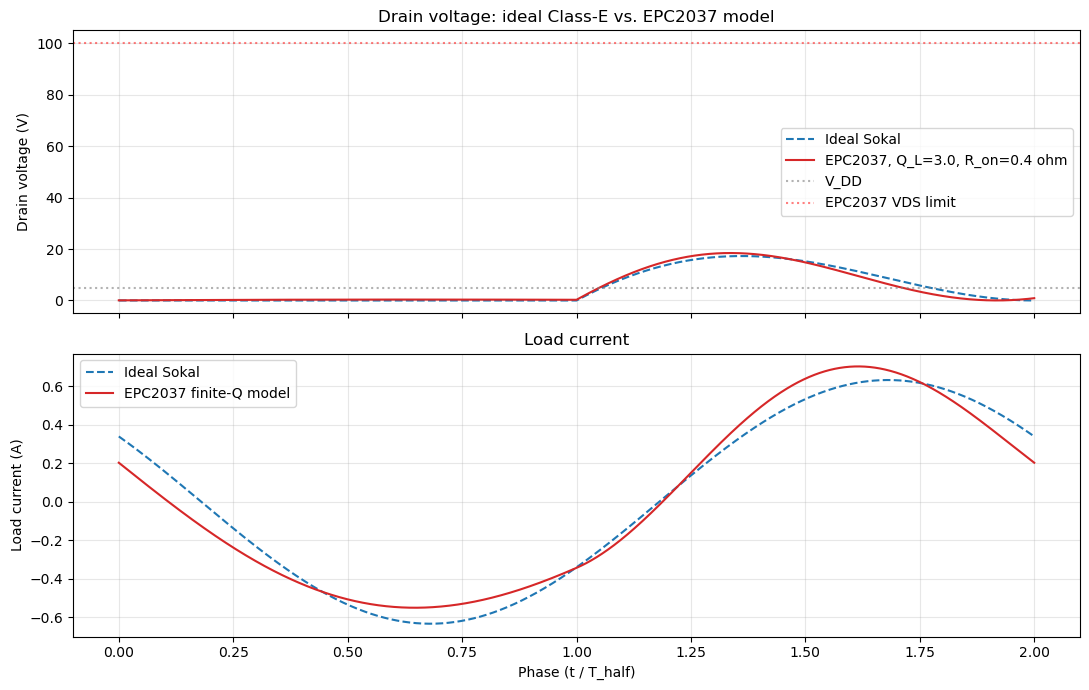

In [4]:
# ============================================================
# CELL 4 — EPC2037 PERFORMANCE AND ENERGY BALANCE
# ============================================================

# ------------------------------------------------------------
# Ideal vs. practical waveform comparison
# ------------------------------------------------------------

print(
    f"\n{'METRIC':<27} | "
    f"{'IDEAL SOKAL':>13} | "
    f"{'EPC2037':>13}"
)

print("-"*60)

print(
    f"{'Drain voltage peak (V)':<27} | "
    f"{sokal['v_D'].max():>13.3f} | "
    f"{honest['v_D_peak']:>13.3f}"
)

print(
    f"{'Drain voltage at turn-on':<27} | "
    f"{sokal['v_D'][0]:>13.4f} | "
    f"{honest['v_D_turnon']:>13.4f}"
)

print(
    f"{'Load current peak (A)':<27} | "
    f"{I_R:>13.4f} | "
    f"{honest['i_L'].max():>13.4f}"
)

print(
    f"{'Load current at turn-on':<27} | "
    f"{I_R*np.sin(phi_sk):>13.4f} | "
    f"{honest['i_L_turnon']:>13.4f}"
)

# ------------------------------------------------------------
# Power calculations
# ------------------------------------------------------------

P_load_0 = np.trapezoid(
    honest["i_L"]**2 * R_opt,
    honest["t"]
) / T

P_Ron_0 = R_on_typ * np.trapezoid(
    honest["i_sw"]**2,
    honest["t"]
) / T

# Approximate capacitive turn-on energy.
# Assumes complete discharge of the equivalent
# linear shunt capacitance at switch turn-on.
#
# This is not a nonlinear EPC2037 Eoss model.

P_ZVS_0 = (
    0.5 * C_sh
    * honest["v_D_turnon"]**2
    * f0
)

P_in_0 = V_DD * I_DC_h

P_total_0 = P_in_0 + P_gate

eta_drain = P_load_0 / P_in_0

eta_system = P_load_0 / P_total_0

balance_0 = (
    P_in_0
    - P_load_0
    - P_Ron_0
    - P_ZVS_0
)

# ------------------------------------------------------------
# Energy balance report
# ------------------------------------------------------------

print(f"\nENERGY BALANCE: EPC2037, Q_L={Q_L}")
print("------------------------------------")

print(f"DC supply power       = {P_in_0*1e3:9.3f} mW")
print(f"Gate-drive power      = {P_gate*1e3:9.3f} mW")
print(f"Total input power     = {P_total_0*1e3:9.3f} mW")

print(f"Load power            = {P_load_0*1e3:9.3f} mW")
print(f"ON-resistance loss    = {P_Ron_0*1e3:9.3f} mW")
print(f"Turn-on energy loss   = {P_ZVS_0*1e3:9.3f} mW")

print(f"Drain balance         = {balance_0*1e3:+9.4f} mW")

print(f"Drain efficiency      = {eta_drain*100:9.2f} %")
print(f"System efficiency     = {eta_system*100:9.2f} %")

# ------------------------------------------------------------
# EPC2037 operating-limit checks
# ------------------------------------------------------------

print("\nEPC2037 OPERATING LIMIT CHECK")
print("-----------------------------")

print(
    f"Peak drain voltage = "
    f"{honest['v_D_peak']:.3f} V"
)

print(
    f"Maximum rated drain voltage = "
    f"{V_DS_max:.1f} V"
)

print(
    f"Drain voltage utilization = "
    f"{100*honest['v_D_peak']/V_DS_max:.2f} %"
)

print(
    f"Peak switch current = "
    f"{honest['i_sw'].max():.3f} A"
)

print(
    f"Continuous current rating = "
    f"{I_D_max:.2f} A"
)

print(
    "Note: peak switching current must be checked "
    "against pulsed-current and thermal conditions."
)

# ------------------------------------------------------------
# Waveform plots
# ------------------------------------------------------------

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

# Drain voltage
ax[0].plot(
    theta/np.pi,
    sokal["v_D"],
    "C0--",
    lw=1.5,
    label="Ideal Sokal"
)

ax[0].plot(
    honest["t"]/T_half,
    honest["v_D"],
    "C3-",
    lw=1.5,
    label=f"EPC2037, Q_L={Q_L}, R_on={R_on_typ} ohm"
)

ax[0].axhline(
    V_DD,
    color="gray",
    ls=":",
    alpha=0.6,
    label="V_DD"
)

ax[0].axhline(
    V_DS_max,
    color="red",
    ls=":",
    alpha=0.5,
    label="EPC2037 VDS limit"
)

ax[0].set_ylabel("Drain voltage (V)")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[0].set_title(
    "Drain voltage: ideal Class-E vs. EPC2037 model"
)

# Load current
ax[1].plot(
    theta/np.pi,
    sokal["i_L"],
    "C0--",
    lw=1.5,
    label="Ideal Sokal"
)

ax[1].plot(
    honest["t"]/T_half,
    honest["i_L"],
    "C3-",
    lw=1.5,
    label="EPC2037 finite-Q model"
)

ax[1].set_xlabel("Phase (t / T_half)")
ax[1].set_ylabel("Load current (A)")
ax[1].legend()
ax[1].grid(alpha=0.3)

ax[1].set_title("Load current")

plt.tight_layout()
plt.show()


EPC2037 ON-RESISTANCE SWEEP
---------------------------
  R_on |     I_DC |   V_Dpk |    I_pk |   P_load |    P_Ron |   P_ZVS |     P_in |   eta_D |  eta_sys |   balance
----------------------------------------------------------------------------------------------------------------
  0.00 |   377.54 |   19.36 |   0.963 |  1830.54 |     0.00 |    0.55 |  1831.09 |  99.97% |   99.53% |    -0.001
  0.10 |   371.90 |   19.12 |   0.949 |  1773.15 |    29.83 |    0.75 |  1803.70 |  98.31% |   97.87% |    -0.024
  0.20 |   366.42 |   18.89 |   0.934 |  1718.35 |    57.88 |    0.96 |  1777.13 |  96.69% |   96.26% |    -0.064
  0.30 |   361.10 |   18.67 |   0.920 |  1665.99 |    84.26 |    1.19 |  1751.33 |  95.13% |   94.69% |    -0.120
  0.40 |   355.93 |   18.45 |   0.906 |  1615.93 |   109.08 |    1.44 |  1726.27 |  93.61% |   93.17% |    -0.189
  0.55 |   348.45 |   18.14 |   0.887 |  1544.86 |   143.61 |    1.84 |  1690.00 |  91.41% |   90.98% |    -0.316
  0.70 |   341.28 |   17.84 |   

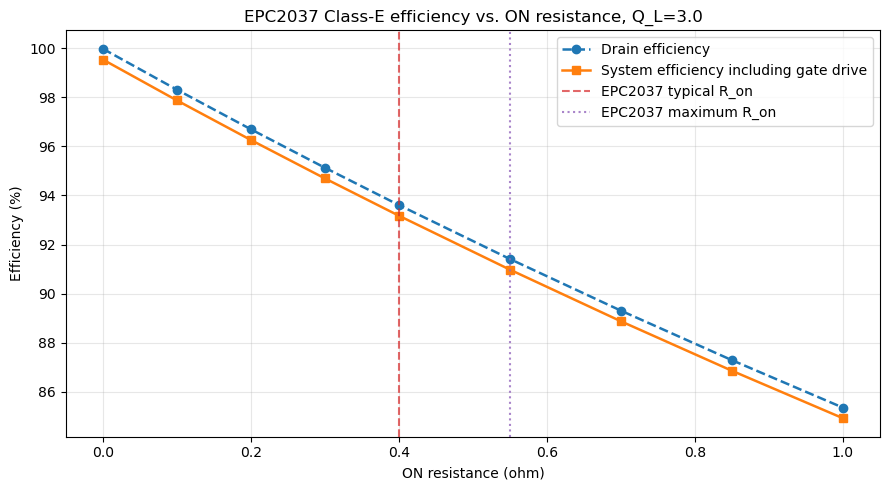

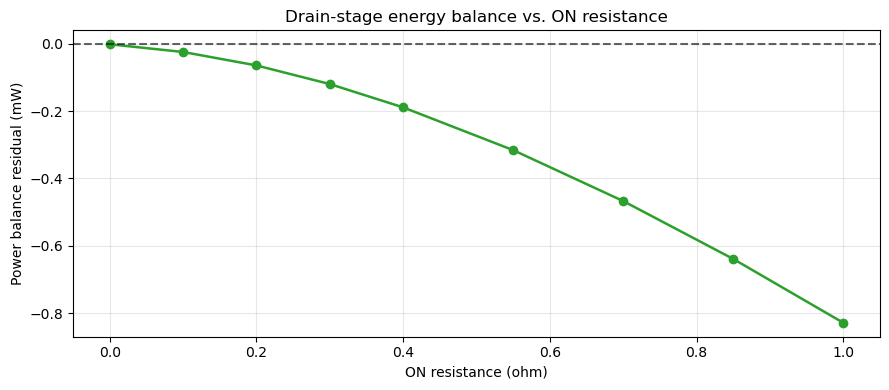


FINAL EPC2037 NOMINAL OPERATING POINT
-------------------------------------
Switching frequency = 14.00 MHz
Supply voltage = 4.85 V
Target output power = 1.650 W
Calculated load power = 1.6159 W
R_on = 0.400 ohm
DC current = 355.931 mA
Peak drain voltage = 18.450 V
Peak switch current = 0.906 A
Drain efficiency = 93.61 %
System efficiency = 93.17 %
Drain energy balance residual = -0.1889 mW


In [5]:
# ============================================================
# CELL 5 — EPC2037 EFFICIENCY VS. ON RESISTANCE
# ============================================================

R_on_values = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.55,
    0.7,
    0.85,
    1.0
]

results = []

# ------------------------------------------------------------
# Resistance sweep
# ------------------------------------------------------------

print("\nEPC2037 ON-RESISTANCE SWEEP")
print("---------------------------")

header = (
    f"{'R_on':>6} | "
    f"{'I_DC':>8} | "
    f"{'V_Dpk':>7} | "
    f"{'I_pk':>7} | "
    f"{'P_load':>8} | "
    f"{'P_Ron':>8} | "
    f"{'P_ZVS':>7} | "
    f"{'P_in':>8} | "
    f"{'eta_D':>7} | "
    f"{'eta_sys':>8} | "
    f"{'balance':>9}"
)

print(header)
print("-"*112)

for R_on in R_on_values:

    # Self-consistent operating point
    h, I_dc, resid = solve_steady_state(R_on)

    # Output load power
    P_load = np.trapezoid(
        h["i_L"]**2 * R_opt,
        h["t"]
    ) / T

    # Switch conduction loss
    P_Ron = R_on * np.trapezoid(
        h["i_sw"]**2,
        h["t"]
    ) / T

    # Approximate capacitive turn-on loss
    P_ZVS = (
        0.5 * C_sh
        * h["v_D_turnon"]**2
        * f0
    )

    # Input power
    P_in = V_DD * I_dc

    P_total = P_in + P_gate

    # Efficiencies
    eta_drain = P_load / P_in

    eta_system = P_load / P_total

    # Drain-stage balance
    balance = (
        P_in
        - P_load
        - P_Ron
        - P_ZVS
    )

    results.append({

        "R_on": R_on,

        "I_DC": I_dc,

        "V_peak": h["v_D_peak"],

        "I_peak": h["i_sw"].max(),

        "P_load": P_load,

        "P_Ron": P_Ron,

        "P_ZVS": P_ZVS,

        "P_in": P_in,

        "eta_drain": eta_drain,

        "eta_system": eta_system,

        "balance": balance,

        "residual": resid

    })

    print(
        f"{R_on:6.2f} | "
        f"{I_dc*1e3:8.2f} | "
        f"{h['v_D_peak']:7.2f} | "
        f"{h['i_sw'].max():7.3f} | "
        f"{P_load*1e3:8.2f} | "
        f"{P_Ron*1e3:8.2f} | "
        f"{P_ZVS*1e3:7.2f} | "
        f"{P_in*1e3:8.2f} | "
        f"{eta_drain*100:6.2f}% | "
        f"{eta_system*100:7.2f}% | "
        f"{balance*1e3:+9.3f}"
    )


# ------------------------------------------------------------
# Efficiency comparison plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    [r["R_on"] for r in results],
    [100*r["eta_drain"] for r in results],
    "o--",
    lw=1.8,
    label="Drain efficiency"
)

ax.plot(
    [r["R_on"] for r in results],
    [100*r["eta_system"] for r in results],
    "s-",
    lw=1.8,
    label="System efficiency including gate drive"
)

ax.axvline(
    R_on_typ,
    color="C3",
    ls="--",
    alpha=0.7,
    label="EPC2037 typical R_on"
)

ax.axvline(
    R_on_max,
    color="C4",
    ls=":",
    alpha=0.8,
    label="EPC2037 maximum R_on"
)

ax.set_xlabel("ON resistance (ohm)")
ax.set_ylabel("Efficiency (%)")

ax.set_title(
    f"EPC2037 Class-E efficiency vs. ON resistance, Q_L={Q_L}"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Drain-stage energy balance plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    [r["R_on"] for r in results],
    [r["balance"]*1e3 for r in results],
    "o-",
    lw=1.8,
    color="C2"
)

ax.axhline(
    0,
    color="black",
    ls="--",
    alpha=0.6
)

ax.set_xlabel("ON resistance (ohm)")
ax.set_ylabel("Power balance residual (mW)")

ax.set_title(
    "Drain-stage energy balance vs. ON resistance"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Final nominal operating point summary
# ------------------------------------------------------------

nominal = min(
    results,
    key=lambda r: abs(r["R_on"] - R_on_typ)
)

print("\nFINAL EPC2037 NOMINAL OPERATING POINT")
print("-------------------------------------")

print(f"Switching frequency = {f0/1e6:.2f} MHz")
print(f"Supply voltage = {V_DD:.2f} V")
print(f"Target output power = {P_out:.3f} W")
print(f"Calculated load power = {nominal['P_load']:.4f} W")

print(f"R_on = {nominal['R_on']:.3f} ohm")

print(f"DC current = {nominal['I_DC']*1e3:.3f} mA")

print(f"Peak drain voltage = {nominal['V_peak']:.3f} V")

print(f"Peak switch current = {nominal['I_peak']:.3f} A")

print(
    f"Drain efficiency = "
    f"{nominal['eta_drain']*100:.2f} %"
)

print(
    f"System efficiency = "
    f"{nominal['eta_system']*100:.2f} %"
)

print(
    f"Drain energy balance residual = "
    f"{nominal['balance']*1e3:+.4f} mW"
)